# **Práctica de Evaluación - Machine Learning**

#### 1. Librerías

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import itertools

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, ExtraTreesClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, recall_score, make_scorer
import os
import time
from scipy.stats import chi2_contingency

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')
RANDOM_STATE=42

#Colores fijos para cada estado de la bomba en todas las gráficas
ESTADOS = ['functional', 'functional needs repair', 'non functional']
COLORES = {'functional': '#2a9d8f', 'functional needs repair': '#e9c46a', 'non functional': '#e76f51'}

#### 2. Cargar los datos

In [2]:
#Los datos no se incluyen en el repositorio (las reglas de la competición no permiten redistribuirlos).
#Se descargan en https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/data/
#y se guardan en la carpeta datos/ con sus nombres originales.
DATOS = 'datos'
FICHEROS = ['Training Set Values.csv', 'Training Set Labels.csv', 'Test Set Values.csv']
faltan = [f for f in FICHEROS if not os.path.exists(os.path.join(DATOS, f))]
assert not faltan, f"Descarga estos ficheros de DrivenData y guárdalos en '{DATOS}/': {faltan}"

train = pd.read_csv(os.path.join(DATOS, 'Training Set Values.csv'))
labels = pd.read_csv(os.path.join(DATOS, 'Training Set Labels.csv'))
test = pd.read_csv(os.path.join(DATOS, 'Test Set Values.csv'))

print('train:', train.shape)
print('labels:', labels.shape)
print('test:', test.shape)

#Tipos de variables (sin mostrar filas de los datos)
pd.DataFrame({'tipo': train.dtypes.astype(str), 'valores_unicos': train.nunique()})

train: (59400, 40)
labels: (59400, 2)
test: (14850, 40)


,tipo,valores_unicos
id,int64,59400
amount_tsh,float64,98
date_recorded,str,356
funder,str,1896
gps_height,int64,2428
installer,str,2145
longitude,float64,57516
latitude,float64,57517
wpt_name,str,37399
num_private,int64,65


Tras cargar los archivos observo que el conjunto train contiene 59,400 observaciones (bombas) y 40 variables explicativas. El conjunto test contiene 14,850 observaciones y las mismas 40 variables explicativas.

Al revisar las variables, observo una gran variedad de variables que describen cada bomba de agua. Tenemos variables geográficas: **longitude**, **latitude**, **gps_height**, **region**, **region_code**,**lga**, **district_code**, y **ward**. Estas variables proprocionan información sobre la localizacion física de casa bomba.

Las siguientes variables describen características relacionadas con la infraestructura y funcionamiento de la bomba: **amount_tsh**, **construction_year**, **extraction_type**, **source** y **waterpoint_type**.

Hay variables que permiten conocer información sobre la financiación, instalación y gestión de la bomba: **funder**, **quantity**, **installer**, **scheme_managemet**, **payment** y **permit**.

También observo la presencia de variables duplicadas que contienen la misma información: **extraction_type**, **extraction_type_group**, **extraction_type_class**, **payment**, **payment_type**, **quantity**, **quantity_group**, **source**, **source_type**, **waterpoint_type** y **waterpoint_type_group**.


#### 3. Análisis exploratorio de datos

In [3]:
train.info()

<class 'pandas.DataFrame'>
RangeIndex: 59400 entries, 0 to 59399
Data columns (total 40 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     59400 non-null  int64  
 1   amount_tsh             59400 non-null  float64
 2   date_recorded          59400 non-null  str    
 3   funder                 55763 non-null  str    
 4   gps_height             59400 non-null  int64  
 5   installer              55745 non-null  str    
 6   longitude              59400 non-null  float64
 7   latitude               59400 non-null  float64
 8   wpt_name               59398 non-null  str    
 9   num_private            59400 non-null  int64  
 10  basin                  59400 non-null  str    
 11  subvillage             59029 non-null  str    
 12  region                 59400 non-null  str    
 13  region_code            59400 non-null  int64  
 14  district_code          59400 non-null  int64  
 15  lga          

Hay un total de 40 variables y un volumen de 59,400 registros. En cuanto a los tipos de datos, se observa que existen 10 variables numéricas: **id**, **amount_tsh**, **gps_height**, **longitude**, **latitude**, **num_private**, **region_code**, **district_code**, **population**, y **construction_year**. Las 30 variables restantes son categóricas.

También podemos observar que las siguientes variables presentan valores nulos: **funder**, **installer**, **wpt_name**, **subvillage**, **public_meeting**, **scheme_management**, **scheme_name**, y **permit**.  

Será necesario tratar los valores faltantes y revisar la cardinalidad de las variables categóricas antes de la fase de modelado. También, será necesario codificar las categóricas, ya que son muchas.

Aunque **region_code** y **district_code** estan categorizadas como variables numericas, no lo son. Se tendran que cambiar a variables categoricas.

In [4]:
nulos = train.isnull().sum()
nulos = nulos[nulos > 0].sort_values(ascending=False)
pct = (nulos / len(train) * 100).round(1)
pd.DataFrame({'nulos': nulos, '%': pct})

,nulos,%
scheme_name,28810,48.5
scheme_management,3878,6.5
installer,3655,6.2
funder,3637,6.1
public_meeting,3334,5.6
permit,3056,5.1
subvillage,371,0.6
wpt_name,2,0.0


El análisis de valores nulos muetra que únicamente 8 de las 40 variables contienen valores faltantes, lo que me indica  que la calidad del dataset, en general, es buena.

Las variable que más me llama la atención es **scheme_name**, con un 48.5% de nulos. Es demasiado para imputar de forma fiable, así que resultará mas conveniente eliminarala directamente en la limpieza.

Por otro lado, el resto de las variables presentan un porcentaje de nulos entre 5% y 7%. Aunque estas variables contienen información incompleta, el porcentaje de datos es relativamente bajo y manejable. Se podran imputar o convertir en una categoría "desconocido" en vez de borrar filas.

status_group
functional                 32259
non functional             22824
functional needs repair     4317
Name: count, dtype: int64

status_group
functional                 54.3
non functional             38.4
functional needs repair     7.3
Name: count, dtype: float64

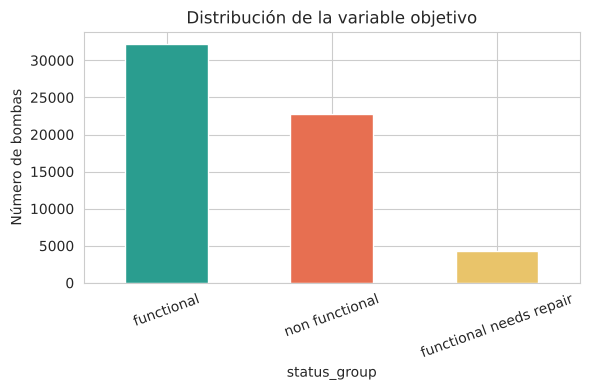

In [5]:
dist = labels['status_group'].value_counts()
display(dist)
display((dist / dist.sum() * 100).round(1))

fig, ax = plt.subplots(figsize=(6, 4))
dist.plot(kind='bar', color=[COLORES[e] for e in dist.index], ax=ax)
ax.set_title('Distribución de la variable objetivo')
ax.set_ylabel('Número de bombas')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

La distribución de **status_group** confirma que el problema está desbalanceado. La mayoría de las bombas (54.3%) están clasificadas como 'functional', mientras que la clase 'functional needs repair' es claramente minoritaria (7.3%).

Este desbalance puede generar varios problemas durante el entrenamiento. El odelo podría aprender con mayor facilidad los patrones asociados a las clases mmayoritarias, las prediccions de la clase minoritaria podrían ser menos precias, y/o el accuracy podría resultar engañoso si el modelo predice correctamente las clases dominantes pero falla en la clase minoritaria.

Por este motivo será importante utilizar métricas como Precision, Recall y F-1 socre durante la fase de evaluación del modelo.

#### 3.1 Visualización de las variables frente al estado de la bomba

Antes de seguir con la limpieza, quiero ver qué variables separan mejor las bombas que funcionan de las que no. Uno el conjunto de entrenamiento con su etiqueta y represento, para cada variable, el porcentaje de bombas en cada estado.

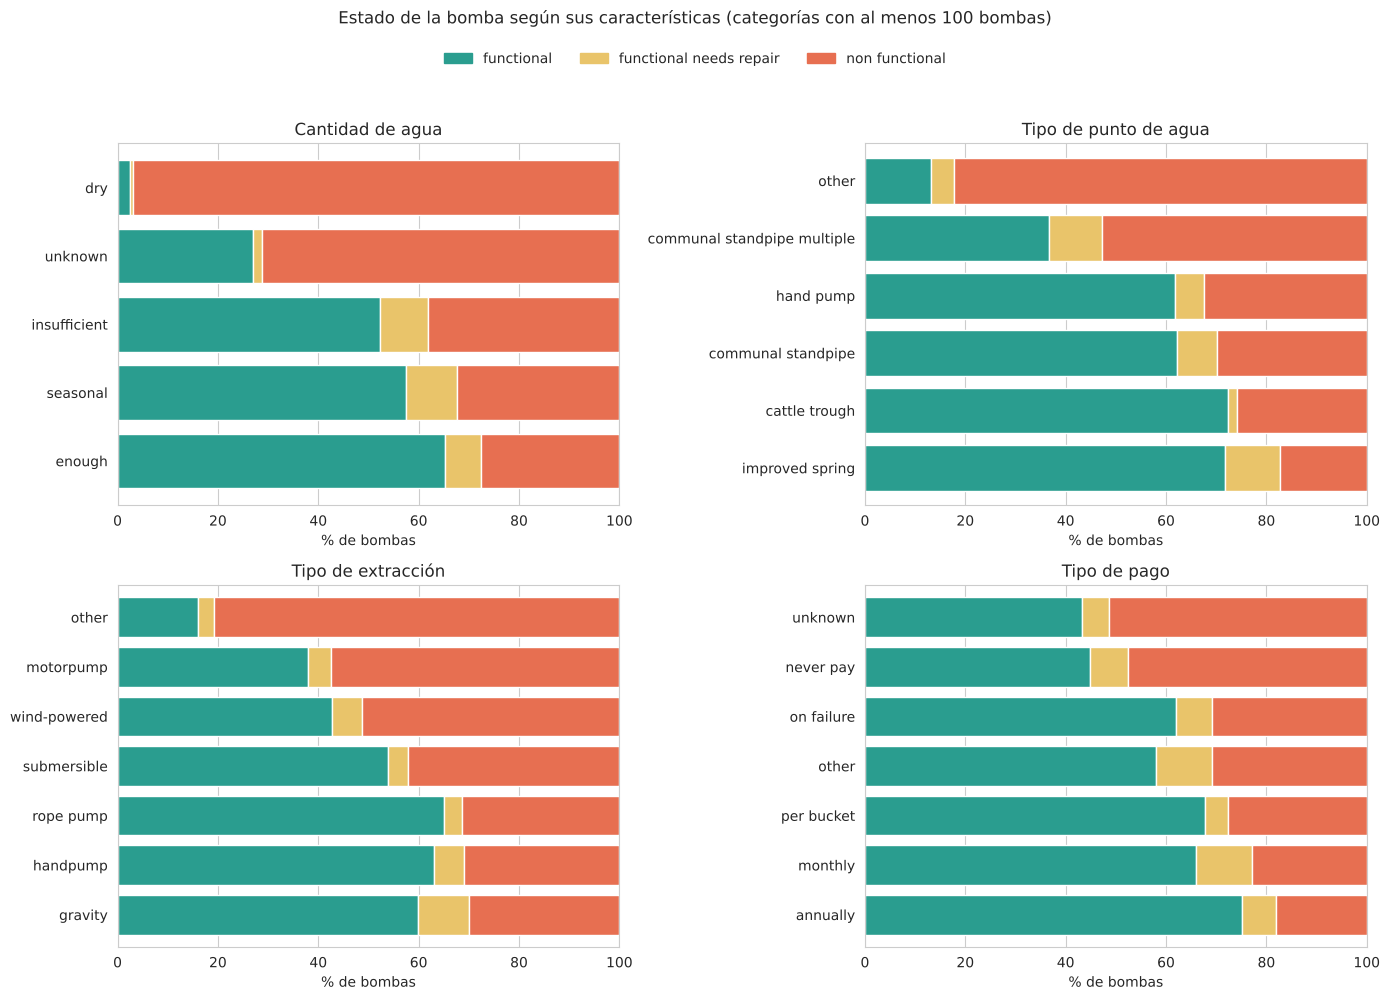

In [6]:
eda = train.merge(labels, on='id')

def proporcion_por(col, ax, titulo, min_n=100):
    tabla = pd.crosstab(eda[col], eda['status_group'], normalize='index')[ESTADOS] * 100
    n = eda[col].value_counts()
    tabla = tabla[n.reindex(tabla.index) >= min_n].sort_values('non functional')
    tabla.plot(kind='barh', stacked=True, color=[COLORES[e] for e in ESTADOS], ax=ax, width=0.8, legend=False)
    ax.set_title(titulo)
    ax.set_xlabel('% de bombas')
    ax.set_ylabel('')
    ax.set_xlim(0, 100)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
proporcion_por('quantity', axes[0, 0], 'Cantidad de agua')
proporcion_por('waterpoint_type', axes[0, 1], 'Tipo de punto de agua')
proporcion_por('extraction_type_class', axes[1, 0], 'Tipo de extracción')
proporcion_por('payment_type', axes[1, 1], 'Tipo de pago')
handles = [plt.Rectangle((0, 0), 1, 1, color=COLORES[e]) for e in ESTADOS]
fig.suptitle('Estado de la bomba según sus características (categorías con al menos 100 bombas)', y=0.995)
fig.legend(handles, ESTADOS, loc='upper center', ncol=3, frameon=False, bbox_to_anchor=(0.5, 0.965))
plt.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

Estas cuatro gráficas muestran diferencias muy claras entre categorías:

- **quantity** es la variable que más separa los estados. El 96.9% de las bombas con cantidad **dry** no funcionan, frente al 27.5% de las que tienen agua **enough**. Una bomba sin agua prácticamente siempre aparece como no funcional.
- En **waterpoint_type**, la categoría **other** tiene un 82% de bombas no funcionales, y **communal standpipe multiple** solo un 36.6% de bombas funcionales, frente al 62.1% de **communal standpipe**. Esto apoya mi decisión de conservar **waterpoint_type** y no la versión agrupada, que mezcla ambos tipos de grifo comunitario.
- En **extraction_type_class**, las bombas con extracción **other** (16% funcionales) y **motorpump** (38%) son las que peor están, mientras que **gravity**, **handpump** y **rope pump** rondan el 60–65%.
- En **payment_type**, las bombas donde se paga de forma periódica (**annually** 75.2% y **monthly** 66.0% funcionales) están mucho mejor que aquellas en las que **never pay** (44.9%). No puedo afirmar que pagar cause un mejor mantenimiento, pero sí que el modo de pago está asociado con el estado de la bomba.

La clase **functional needs repair** es pequeña en todas las categorías, lo que anticipa que será la más difícil de predecir.

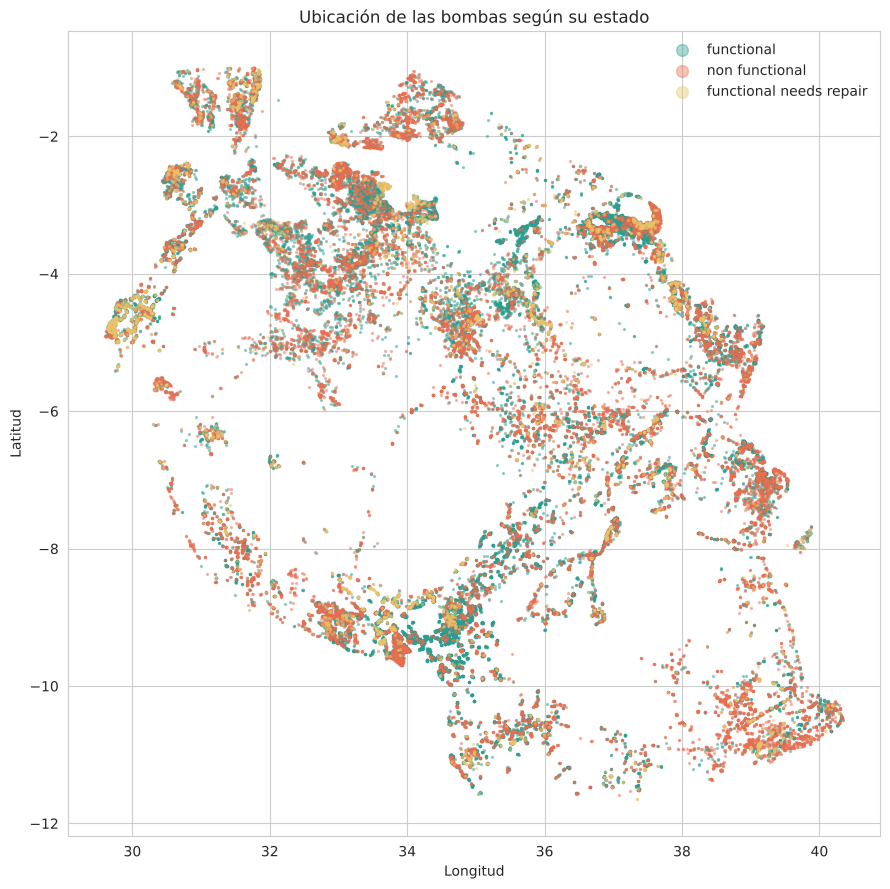

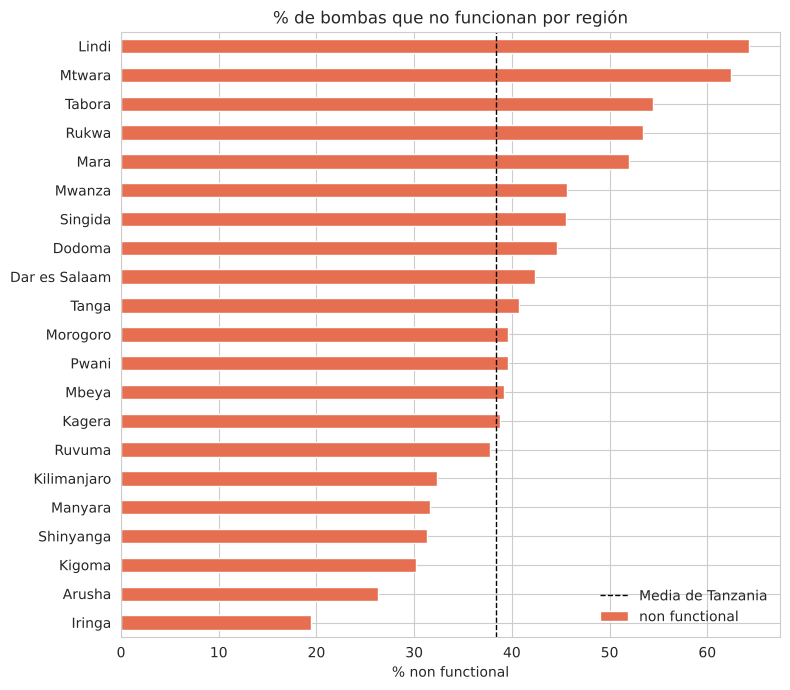

In [7]:
geo = eda[eda['longitude'] > 0]
fig, ax = plt.subplots(figsize=(9, 9))
for estado in ['functional', 'non functional', 'functional needs repair']:
    sub = geo[geo['status_group'] == estado]
    ax.scatter(sub['longitude'], sub['latitude'], s=2, alpha=0.4, color=COLORES[estado], label=estado)
ax.set_title('Ubicación de las bombas según su estado')
ax.set_xlabel('Longitud')
ax.set_ylabel('Latitud')
ax.legend(markerscale=6, frameon=False)
ax.set_aspect('equal')
plt.tight_layout()
plt.show()

pct_region = (pd.crosstab(eda['region'], eda['status_group'], normalize='index')['non functional'] * 100).sort_values()
fig, ax = plt.subplots(figsize=(8, 7))
pct_region.plot(kind='barh', color=COLORES['non functional'], ax=ax)
ax.axvline(eda['status_group'].eq('non functional').mean() * 100, color='black', linestyle='--', linewidth=1, label='Media de Tanzania')
ax.set_title('% de bombas que no funcionan por región')
ax.set_xlabel('% non functional')
ax.set_ylabel('')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

El mapa muestra que las bombas no funcionales no están repartidas al azar: hay zonas donde predominan claramente, sobre todo en el sureste del país.

La gráfica por región lo confirma. La media nacional es un 38.4% de bombas no funcionales, pero varía muchísimo: desde el 19.5% de **Iringa** hasta el 62.4% de **Mtwara** y el 64.2% de **Lindi**. Esto explica por qué **longitude** y **latitude** salen entre las variables más importantes del modelo: la ubicación recoge diferencias regionales de mantenimiento, financiación y acceso que no aparecen directamente en otras variables.

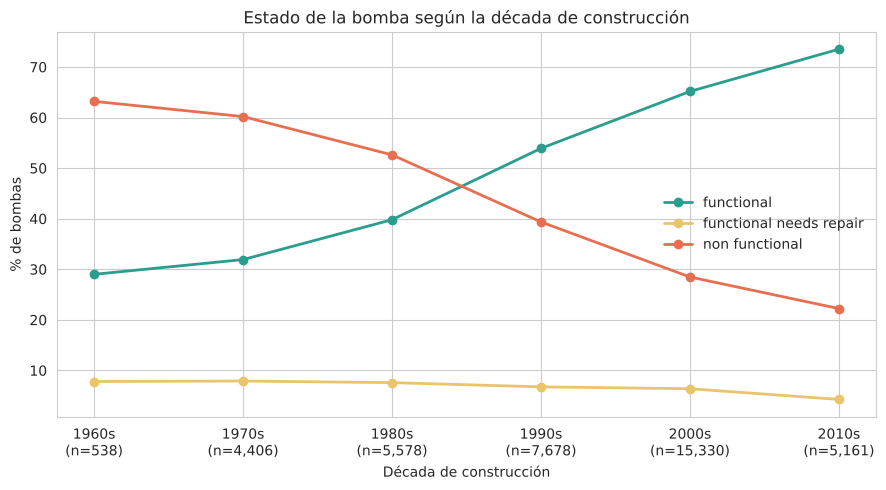

In [8]:
con_año = eda[eda['construction_year'] > 0].copy()
con_año['decada'] = (con_año['construction_year'] // 10 * 10).astype(int)
por_decada = pd.crosstab(con_año['decada'], con_año['status_group'], normalize='index')[ESTADOS] * 100
n_decada = con_año['decada'].value_counts().sort_index()

fig, ax = plt.subplots(figsize=(9, 5))
for estado in ESTADOS:
    ax.plot(por_decada.index, por_decada[estado], marker='o', linewidth=2, color=COLORES[estado], label=estado)
ax.set_title('Estado de la bomba según la década de construcción')
ax.set_xlabel('Década de construcción')
ax.set_ylabel('% de bombas')
ax.set_xticks(por_decada.index)
ax.set_xticklabels([f"{d}s\n(n={n_decada[d]:,})" for d in por_decada.index])
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Para esta gráfica solo uso las bombas con año de construcción conocido, ya que el 34.9% tiene **construction_year = 0**.

La relación con la antigüedad es muy clara: el 63.2% de las bombas construidas en los años 60 no funcionan, frente al 22.2% de las construidas a partir de 2010. Esto justifica crear la variable **age** en la fase de limpieza.

En cambio, el porcentaje de **functional needs repair** se mantiene entre el 4% y el 8% en todas las décadas. La antigüedad ayuda a distinguir las bombas que funcionan de las que no, pero no a identificar las que necesitan reparación.

In [9]:
#Cardinalidad de variables categoricas
cardinalidad = train.select_dtypes(include=['object', 'string']).nunique().sort_values(ascending=False)
display(cardinalidad.to_frame('categorías únicas'))

#Categorías más frecuentes solo para las variables de baja cardinalidad
cat_cols_original = train.select_dtypes(include=['object', 'string']).columns
for col in cat_cols_original:
    if train[col].nunique() <= 30:
        print(f"\n{col}  ({train[col].nunique()} categorías únicas):")
        print(train[col].value_counts().head(10))

,categorías únicas
wpt_name,37399
subvillage,19287
scheme_name,2695
installer,2145
ward,2092
funder,1896
date_recorded,356
lga,125
region,21
extraction_type,18



basin  (9 categorías únicas):
basin
Lake Victoria              10248
Pangani                     8940
Rufiji                      7976
Internal                    7785
Lake Tanganyika             6432
Wami / Ruvu                 5987
Lake Nyasa                  5085
Ruvuma / Southern Coast     4493
Lake Rukwa                  2454
Name: count, dtype: int64

region  (21 categorías únicas):
region
Iringa         5294
Shinyanga      4982
Mbeya          4639
Kilimanjaro    4379
Morogoro       4006
Arusha         3350
Kagera         3316
Mwanza         3102
Kigoma         2816
Ruvuma         2640
Name: count, dtype: int64

public_meeting  (2 categorías únicas):
public_meeting
True     51011
False     5055
Name: count, dtype: int64

recorded_by  (1 categorías únicas):
recorded_by
GeoData Consultants Ltd    59400
Name: count, dtype: int64

scheme_management  (11 categorías únicas):
scheme_management
VWC                 36793
WUG                  5206
Water authority      3153
WUA            

quality_group
good        50818
salty        5195
unknown      1876
milky         804
colored       490
fluoride      217
Name: count, dtype: int64

quantity  (5 categorías únicas):
quantity
enough          33186
insufficient    15129
dry              6246
seasonal         4050
unknown           789
Name: count, dtype: int64

quantity_group  (5 categorías únicas):
quantity_group
enough          33186
insufficient    15129
dry              6246
seasonal         4050
unknown           789
Name: count, dtype: int64

source  (10 categorías únicas):
source
spring                  17021
shallow well            16824
machine dbh             11075
river                    9612
rainwater harvesting     2295
hand dtw                  874
lake                      765
dam                       656
other                     212
unknown                    66
Name: count, dtype: int64

source_type  (7 categorías únicas):
source_type
spring                  17021
shallow well            16824
borehol

Observo una gran diversidad en la cardinalidad de las variables categóricas. Mientras algunas variables poseen únicamente entre ~2 y 10 categorías, otras contienen miles de valores distintos.

Las siguientes variables presentan un número muy elevado de categorías: **wpt_name** (37,399), **subvillage** (19,287), **scheme_name** (2,695), **ward** (2,092), **installer** (2,145) y **funder** (1,896).

Será necesario evaluar si conviene mantener las variables con una cardinalidad muy elevada, agrupar las categorías poco frecuentes, codificar, o eliminarlas si no aportan suficiente capacidad predictiva.

Aqui puede ver también que **quantity** y **quantity_group**, y **payment** y **payment_type** son identicas.

In [10]:
pd.crosstab(train['extraction_type_group'], train['extraction_type_class'])

extraction_type_class,gravity,handpump,motorpump,other,rope pump,submersible,wind-powered
extraction_type_group,,,,,,,
afridev,0,1770,0,0,0,0,0
gravity,26780,0,0,0,0,0,0
india mark ii,0,2400,0,0,0,0,0
india mark iii,0,98,0,0,0,0,0
mono,0,0,2865,0,0,0,0
nira/tanira,0,8154,0,0,0,0,0
other,0,0,0,6430,0,0,0
other handpump,0,364,0,0,0,0,0
other motorpump,0,0,122,0,0,0,0


Para estudiar la relación entre las variables **extraction_type**, **extraction_type_group** y **extraction_type_class**, decidí construir una tabla cruzada.

Los resultados muestran que cada categoría de **extraction_type_group** pertenece a una categoría de **extraction_type_class**. Esto indica que ambas variables describe el mismo concepto con distintos niveles de detalle.

La tabla
cruzada confirma que **extraction_type_class** es una agregación perfecta de **extraction_type_group**.

Con el objetivo de reducir la complejidad de mi modelo y evitar información duplicada, decidí conserva la variable **extraction_type_class** y eliminar **extraction_type_group** y **extraction_type**.

In [11]:
pd.crosstab(train['water_quality'], train['quality_group'])

quality_group,colored,fluoride,good,milky,salty,unknown
water_quality,,,,,,
coloured,490,0,0,0,0,0
fluoride,0,200,0,0,0,0
fluoride abandoned,0,17,0,0,0,0
milky,0,0,0,804,0,0
salty,0,0,0,0,4856,0
salty abandoned,0,0,0,0,339,0
soft,0,0,50818,0,0,0
unknown,0,0,0,0,0,1876


Dado que ambas variables contienen esencialmente la misma información, decidi conservar **quality_group** y eliminar **water_quality**.

Esta variable reduce la cardinalidad (6 categorías frente a 8), la redundancia del dataset y simplifica el procese de modelado.

In [12]:
pd.crosstab(train['source'], train['source_type'])

source_type,borehole,dam,other,rainwater harvesting,river/lake,shallow well,spring
source,,,,,,,
dam,0,656,0,0,0,0,0
hand dtw,874,0,0,0,0,0,0
lake,0,0,0,0,765,0,0
machine dbh,11075,0,0,0,0,0,0
other,0,0,212,0,0,0,0
rainwater harvesting,0,0,0,2295,0,0,0
river,0,0,0,0,9612,0,0
shallow well,0,0,0,0,0,16824,0
spring,0,0,0,0,0,0,17021


In [13]:
pd.crosstab(train['source'], train['source_class'])

source_class,groundwater,surface,unknown
source,,,
dam,0,656,0
hand dtw,874,0,0
lake,0,765,0
machine dbh,11075,0,0
other,0,0,212
rainwater harvesting,0,2295,0
river,0,9612,0
shallow well,16824,0,0
spring,17021,0,0


In [14]:
pd.crosstab(train['source_class'], train['source_type'])

source_type,borehole,dam,other,rainwater harvesting,river/lake,shallow well,spring
source_class,,,,,,,
groundwater,11949,0,0,0,0,16824,17021
surface,0,656,0,2295,10377,0,0
unknown,0,0,278,0,0,0,0


Tras analizar la relacion entre **source**, **source_type** y **source_class**, decidi convservar **source_type**.

**Source_type** resume adecuadamente la información contenida en **source** y conserva un nivel de detalle mayor a **source_class**.

In [15]:
pd.crosstab(train['waterpoint_type'], train['waterpoint_type_group'])

waterpoint_type_group,cattle trough,communal standpipe,dam,hand pump,improved spring,other
waterpoint_type,,,,,,
cattle trough,116,0,0,0,0,0
communal standpipe,0,28522,0,0,0,0
communal standpipe multiple,0,6103,0,0,0,0
dam,0,0,7,0,0,0
hand pump,0,0,0,17488,0,0
improved spring,0,0,0,0,784,0
other,0,0,0,0,0,6380


Esta es la única familia donde la diferencia es realmente pequeña: **waterpoint_type_group** solo fusiona communal standpipe y communal standpipe multiple en una sola categoría. El resto es idéntico y la categoría dam con solo 7 registros sigue igual de diminuta en ambas versiones, así que ninguna de las dos "arregla" ese problema.

La principal cuestión aquí es determinar si el hecho de que un grifo comunitario sea "múltiple" es relevante para saber si la bomba falla. Yo creo que sí puede serlo, ya que un mayor número de usos resultaría en un mayor desgaste de la infraestructura.

Por esta razón decidí conservar la variable **waterpoint_type**, y eliminar **waterpoint_type_group**.

In [16]:
print('construction_year == 0:', (train.construction_year==0).sum(), f"({(train.construction_year==0).mean()*100:.1f}%)")
print('gps_height == 0     :', (train.gps_height==0).sum(), f"({(train.gps_height==0).mean()*100:.1f}%)")
print('population == 0     :', (train.population==0).sum(), f"({(train.population==0).mean()*100:.1f}%)")
print('latitude ~ 0        :', (train.latitude.abs()<1).sum())
print('longitude == 0      :', (train.longitude==0).sum())
print('recorded_by valores únicos:', train['recorded_by'].unique())
print('num_private == 0 en el', round((train['num_private']==0).mean()*100,1), '% de los registros')

construction_year == 0: 20709 (34.9%)
gps_height == 0     : 20438 (34.4%)
population == 0     : 21381 (36.0%)
latitude ~ 0        : 1819
longitude == 0      : 1812
recorded_by valores únicos: <StringArray>
['GeoData Consultants Ltd']
Length: 1, dtype: str
num_private == 0 en el 98.7 % de los registros


Mas de un tercio de las filas tienen **construction_year**, **gps_height**, o **population** en cero y unas 1,800 filas tienen coordenadas que son imposibles de estar en Tanzania.

**recorded_by** tiene un único valor entonces la eliminare. **num_private** tiene un 0 en el 98.7% de registros asi que la eliminare de la matriz de correlacion para las variables numericas.

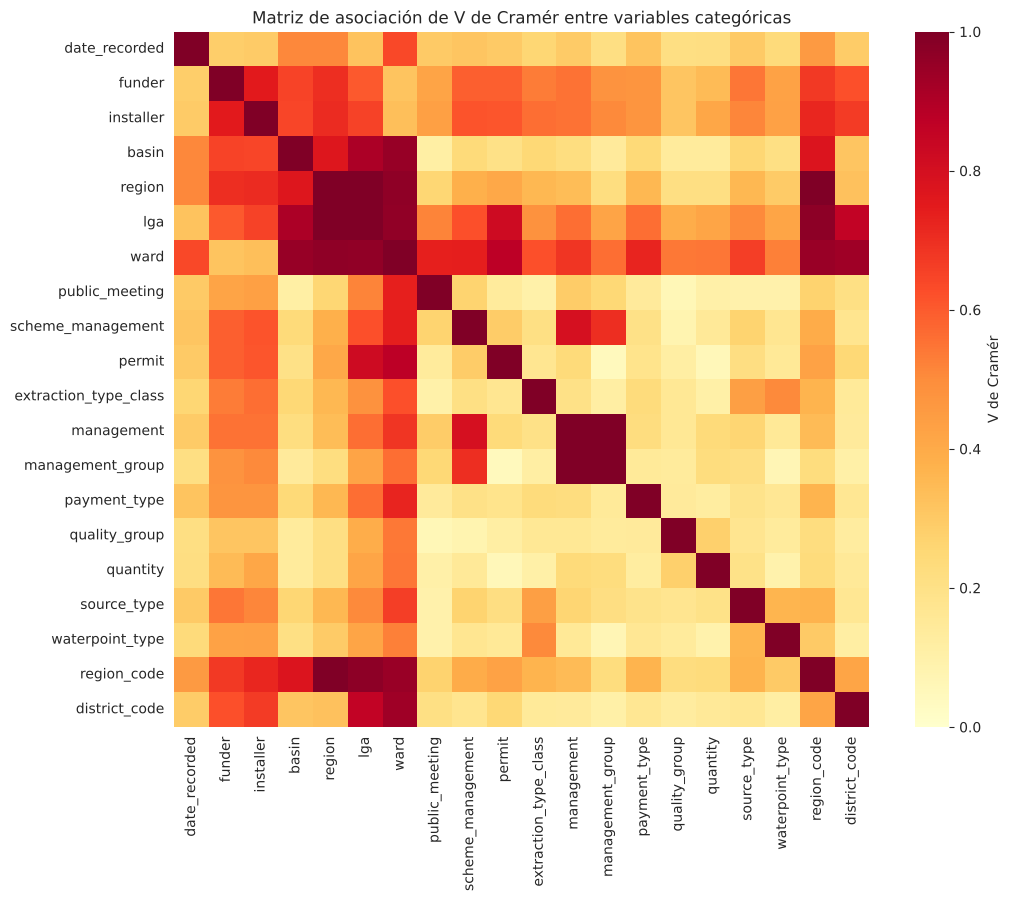

,Variable_1,Variable_2,V_de_Cramér
0,management,management_group,0.999941
1,region,lga,0.999124
2,region,region_code,0.998095
3,lga,region_code,0.971860
4,region,ward,0.967637
5,lga,ward,0.963667
6,basin,ward,0.950852
7,ward,region_code,0.947717
8,ward,district_code,0.936975
9,basin,lga,0.906756


In [17]:
def cramers_v(x, y):
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla)[0]
    n = tabla.sum().sum()
    r, k = tabla.shape
    phi2 = chi2 / n
    phi2_corr = max(0, phi2 - ((k - 1) * (r - 1)) / (n - 1))
    r_corr = r - ((r - 1) ** 2) / (n - 1)
    k_corr = k - ((k - 1) ** 2) / (n - 1)
    return np.sqrt(phi2_corr / max(1e-10, min(k_corr - 1, r_corr - 1)))

ya_eliminadas = ['extraction_type', 'extraction_type_group', 'payment', 'water_quality',
                     'quantity_group', 'source', 'source_class', 'waterpoint_type_group']
cardinalidad_extrema = ['wpt_name', 'subvillage', 'scheme_name', 'recorded_by']
cat_preliminares = [c for c in cat_cols_original if c not in ya_eliminadas + cardinalidad_extrema]

#region_code/district_code son codigos administrativos, no cantidades
train_cat = train.copy()
train_cat['region_code'] = train_cat['region_code'].astype(str)
train_cat['district_code'] = train_cat['district_code'].astype(str)
cat_preliminares = cat_preliminares + ['region_code', 'district_code']

n = len(cat_preliminares)
matriz_v = pd.DataFrame(np.eye(n), index=cat_preliminares, columns=cat_preliminares)
for a, b in itertools.combinations(cat_preliminares, 2):
    v = cramers_v(train_cat[a], train_cat[b])
    matriz_v.loc[a, b] = v
    matriz_v.loc[b, a] = v

fig, ax = plt.subplots(figsize=(11, 9))
sns.heatmap(matriz_v, cmap='YlOrRd', vmin=0, vmax=1, square=True,
            xticklabels=True, yticklabels=True, ax=ax, cbar_kws={'label': "V de Cramér"})
ax.set_title("Matriz de asociación de V de Cramér entre variables categóricas")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

pares = [(a, b, matriz_v.loc[a, b]) for a, b in itertools.combinations(cat_preliminares, 2)]
pares.sort(key=lambda t: -t[2])
pd.DataFrame(pares[:15], columns=['Variable_1', 'Variable_2', 'V_de_Cramér'])

La tabla confirma, con datos y no solo por inspección visual, que **management** y **management_group** son prácticamente idénticas (V = 0.9999), una redundancia que justifica eliminar **management_group**. Además, se ve con claridad que Todo el bloque geográfico: **basin, region, region_code, district_code, lga, ward** sale con asociaciones muy altas entre sí, con la mayoría de los pares por encima de 0.9. Esto respalda la decisión de no mantener las seis simultáneamente en el modelo, sino quedarme solo con las que aportan un matiz distinto.

Lo que sí es una novedad interesante frente al análisis anterior es la aparición de **ward-permit** (0.87) y **lga-permit** (0.82) en el top 15: una asociación alta entre variables administrativas y si la bomba tiene permiso legal, que probablemente refleja que la concesión de permisos varía sistemáticamente por zona geográfica.

De las 6 columnas geográficas, decidí conservar **region**, **basin**, **district_code**, **lga** y **ward**. Elimino **region_code`** (prácticamente un duplicado de **region**).

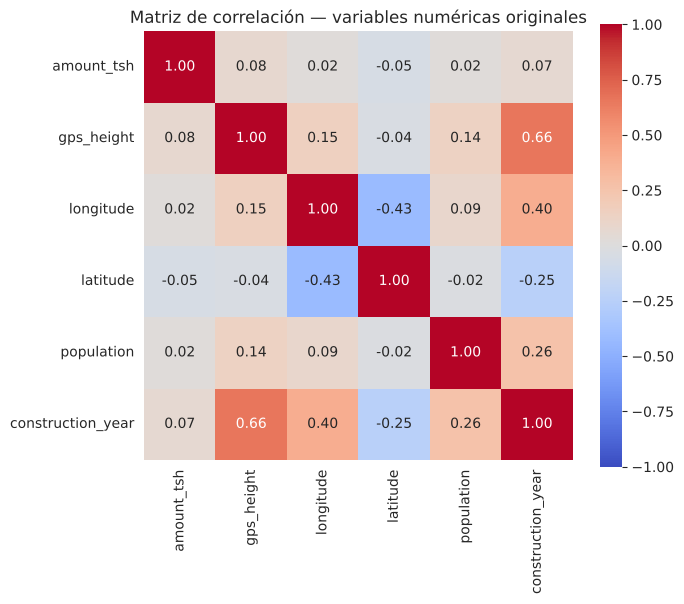

,amount_tsh,gps_height,longitude,latitude,population,construction_year
amount_tsh,1.000000,0.076650,0.022134,-0.052670,0.016288,0.067915
gps_height,0.076650,1.000000,0.149155,-0.035751,0.135003,0.658727
longitude,0.022134,0.149155,1.000000,-0.425802,0.086590,0.396732
latitude,-0.052670,-0.035751,-0.425802,1.000000,-0.022152,-0.245278
population,0.016288,0.135003,0.086590,-0.022152,1.000000,0.260910
construction_year,0.067915,0.658727,0.396732,-0.245278,0.260910,1.000000


In [18]:
num_cols_original = ['amount_tsh', 'gps_height', 'longitude', 'latitude', 'population', 'construction_year']

corr = train[num_cols_original].corr()
fig, ax = plt.subplots(figsize=(7,6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Matriz de correlación — variables numéricas originales')
plt.tight_layout()
plt.show()
corr

Con las variables numéricas originales la mayoría de las correlaciones son débiles. **amount_tsh** no muestra relación relevante con ninguna otra variable, y **population**, **longitude** y **latitude** se mueven de forma bastante independiente entre sí. La excepción llamativa es **gps_height-construction_year** (0.66), una correlación moderada que no esperaraba entre altitud y año de construcción.

Puede ser que esta correlación está inflada por el problema de los ceros "sucios" detectado antes. Lo mismo podría estar pasando, en menor medida, con **longitude/latitude** frente a **construction_year** (0.40 y -0.25).

#### 4. Limpieza y transformación de datos

In [19]:
def preparar_basico(df):
    df = df.copy()

    #Fechas -> año y mes de registro
    df['date_recorded'] = pd.to_datetime(df['date_recorded'])
    df['year_recorded'] = df['date_recorded'].dt.year
    df['month_recorded'] = df['date_recorded'].dt.month
    df = df.drop(columns=['date_recorded'])

    #Ceros imposibles -> NaN
    df['construction_year'] = df['construction_year'].replace(0, np.nan)
    df['gps_height'] = df['gps_height'].replace(0, np.nan)
    df['population'] = df['population'].replace(0, np.nan)
    df.loc[df['latitude'].abs() < 1, 'latitude'] = np.nan
    df.loc[df['longitude'] == 0, 'longitude'] = np.nan

    #Columnas a eliminar
    drop_cols = ['recorded_by', 'wpt_name', 'num_private', 'subvillage', 'scheme_name',
                 'extraction_type', 'extraction_type_group',
                 'payment', 'water_quality', 'quantity_group',
                 'source', 'source_class', 'waterpoint_type_group',
                 'management_group', 'region_code']
    df = df.drop(columns=[c for c in drop_cols if c in df.columns])

    #district_code es un codigo administrativo -> categorico, no numerico
    df['district_code'] = df['district_code'].astype(str)

    #Nulos: relleno con desconocido
    for col in ['funder', 'installer', 'ward']:
        df[col] = df[col].fillna('desconocido')
    cat_cols = df.select_dtypes(include=['object', 'string', 'bool']).columns
    for c in cat_cols:
        if c not in ['funder', 'installer', 'ward']:
            df[c] = df[c].fillna('desconocido').astype(str)

    return df

def ajustar_estadisticas(df_fit):
    stats = {'mediana_region': {}, 'mediana_global': {}, 'frecuencias': {}}
    for col in ['gps_height', 'population', 'latitude', 'longitude', 'construction_year']:
        stats['mediana_region'][col] = df_fit.groupby('region')[col].median()
        stats['mediana_global'][col] = df_fit[col].median()
    for col in ['ward', 'funder', 'installer']:
        stats['frecuencias'][col] = df_fit[col].value_counts()
    return stats

def aplicar_estadisticas(df, stats):
    df = df.copy()

    #Imputacion numerica/geografica con la mediana de region
    for col, mediana_region in stats['mediana_region'].items():
        relleno = df['region'].map(mediana_region).fillna(stats['mediana_global'][col])
        df[col] = df[col].fillna(relleno)

    #Antiguedad de la bomba
    df['age'] = df['year_recorded'] - df['construction_year']
    df = df.drop(columns=['construction_year'])

    #Frequency encoding
    for col, freq in stats['frecuencias'].items():
        df[col + '_freq'] = df[col].map(freq).fillna(0)
        df = df.drop(columns=[col])

    return df

#Preparacion basica de ambos conjuntos
train_base = preparar_basico(train)
test_base = preparar_basico(test)

print('train_base:', train_base.shape, ' test_base:', test_base.shape)
print('Valores nulos que quedan por imputar:', int(train_base.isna().sum().sum()))

train_base: (59400, 26)  test_base: (14850, 26)
Valores nulos que quedan por imputar: 66159


Decidí crear prepara_bascio() para que contenga únicamente transformaciones que no dependen de ninguna estadística calculada sobre los propios datos. Dejé fuera de esta función la imputación de NaN y el frequency encoding, que sí dependen de una estadística y port tanto van en ajustar_estadisticas()/(aplicar_estadisticas(). Estas dos funciones se ejecutan más adelante y solo con el conjunto de entrenamiento.

Al revisar el resultado, veo que train_base queda en 59400, 26 y test_base en 14850, 26. Las mismas 26 columnas en ambos, así que la limpieza básica mantiene el esquema compartido para poder aplicar después las mismas estadísticas a los dos conjuntos. También compruebo que siguen existiendo NaN, que se imputan más adelante.

#### 5. Verificación post-limpieza

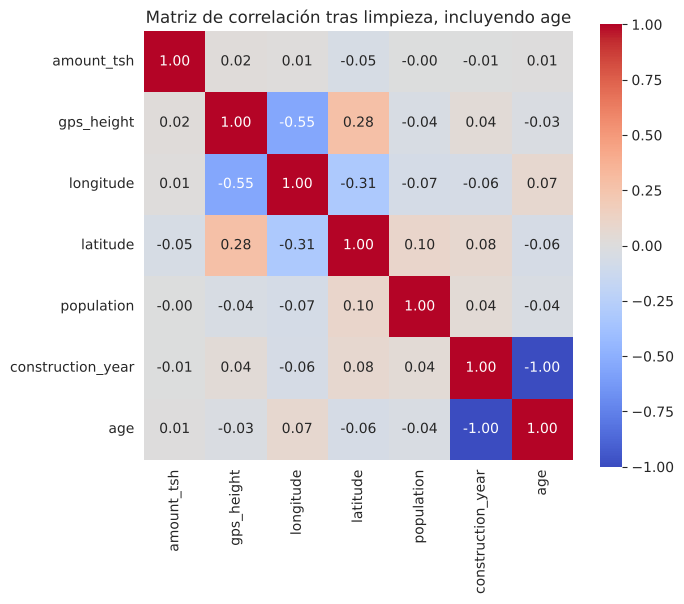

Correlacion age vs construction_year: -0.9958


In [20]:
tmp = train_base.copy()
stats_diag = ajustar_estadisticas(tmp)
tmp_imputado = tmp.copy()
for col, mediana_region in stats_diag['mediana_region'].items():
    relleno = tmp_imputado['region'].map(mediana_region).fillna(stats_diag['mediana_global'][col])
    tmp_imputado[col] = tmp_imputado[col].fillna(relleno)
tmp_imputado['age'] = tmp_imputado['year_recorded'] - tmp_imputado['construction_year']

num_diag = ['amount_tsh', 'gps_height', 'longitude', 'latitude', 'population',
            'construction_year', 'age']
corr_limpia = tmp_imputado[num_diag].corr()

fig, ax = plt.subplots(figsize=(7,6))
sns.heatmap(corr_limpia, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, square=True, ax=ax)
ax.set_title('Matriz de correlación tras limpieza, incluyendo age')
plt.tight_layout()
plt.show()

print("Correlacion age vs construction_year:", corr_limpia.loc['age','construction_year'].round(4))

La correlación entre **age** y **construction_year** es -0.996 (a mayor año de construcción, la bomba es más *nueva* = menos *age*). Calculé **age** como **year_recorded - construction_year**, y como **year_recorded** apenas varía el resultado es casi una transformación lineal exacta de **construction_year**.

Mantener ambas variables en el modelo sería redundante, asi que decidí eliminar **construction_year** y conservar **age**, que es la variable con significado más directo para el problema (antigüedad de la bomba) y ya incorpora toda la información relevante de **construction_year**.

#### 6. Partición train/validación, ajuste de estadística y codificación

In [21]:
y_full = labels.set_index('id').loc[train_base['id'], 'status_group']

#Particion sobre los datos aun sin imputar/codificar
train_base_tr, train_base_val, y_train, y_val = train_test_split(
    train_base, y_full, test_size=0.2, random_state=RANDOM_STATE, stratify=y_full
)

#Ajuste de estadisticas con la porcion de entrenamiento interna
stats_val = ajustar_estadisticas(train_base_tr)

#Aplico esas mismas estadisticas a train interno y a validacion
X_train = aplicar_estadisticas(train_base_tr, stats_val).drop(columns=['id'])
X_val = aplicar_estadisticas(train_base_val, stats_val).drop(columns=['id'])

cat_cols = X_train.select_dtypes(include=['object', 'string']).columns.tolist()
num_cols = [c for c in X_train.columns if c not in cat_cols]

print(f'{len(num_cols)} columnas numericas :', num_cols)
print(f'{len(cat_cols)} columnas categoricas:', cat_cols)

preprocesador = ColumnTransformer([
    ('cat', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1), cat_cols),
], remainder='passthrough')

print('Train:', X_train.shape, ' Validacion:', X_val.shape)

11 columnas numericas : ['amount_tsh', 'gps_height', 'longitude', 'latitude', 'population', 'year_recorded', 'month_recorded', 'age', 'ward_freq', 'funder_freq', 'installer_freq']
14 columnas categoricas: ['basin', 'region', 'district_code', 'lga', 'public_meeting', 'scheme_management', 'permit', 'extraction_type_class', 'management', 'payment_type', 'quality_group', 'quantity', 'source_type', 'waterpoint_type']
Train: (47520, 25)  Validacion: (11880, 25)


Quedan 14 variables categóricas y 11 numéricas. La partición deja 47,520 filas para entrenar y 11,880 para validar. Las estadísticas de imputación y de frecuencia se ajustaron con las 47,520 filas de entrenamiento, no con las 59,400 completas. Esto es para que la validación mida de forma honesta lo que ocurrirá con datos que el proceso de ajuste no ha visto aún.

#### 7. Modelado y comparación de algoritmos

In [22]:
resultados = {}

#Baseline
baseline = DummyClassifier(strategy='most_frequent')
baseline.fit(X_train, y_train)
resultados['Baseline (clase mayoritaria)'] = accuracy_score(y_val, baseline.predict(X_val))

#Random Forest
pipe_rf = Pipeline([
    ('pre', preprocesador),
    ('clf', RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                    random_state=RANDOM_STATE, n_jobs=-1))
])
pipe_rf.fit(X_train, y_train)
resultados['Random Forest'] = accuracy_score(y_val, pipe_rf.predict(X_val))

#HistGradientBoosting
pipe_hgb = Pipeline([
    ('pre', preprocesador),
    ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE, max_iter=300))
])
pipe_hgb.fit(X_train, y_train)
resultados['HistGradientBoosting'] = accuracy_score(y_val, pipe_hgb.predict(X_val))

pd.Series(resultados, name='accuracy').sort_values(ascending=False).to_frame()

,accuracy
Random Forest,0.816667
HistGradientBoosting,0.805640
Baseline (clase mayoritaria),0.543098


Ambos modelos (Random Forest y HistGradientBoosting) superan el baseline, lo cual confirma que las variables sí tienen poder predictivo real sobre el estado de la bomba. Random Forest supera a HistGradientBoosting con su configuración por defecto, asi que lo elijo como algoritmo base y en la siguiente sección afinaré sus hiperparámetros.

#### 7.1 Comparación ampliada de modelos

Para no quedarme solo con dos algoritmos, comparo siete modelos de familias distintas: un modelo lineal (regresión logística), un árbol de decisión individual, tres ensembles de árboles (Random Forest, Random Forest con pesos por clase y Extra Trees) y dos versiones de Gradient Boosting.

Los comparo con validación cruzada estratificada de 5 particiones sobre el conjunto de entrenamiento interno, en lugar de una sola partición, para ver también cuánto varía cada resultado. Además del accuracy (la métrica de la competición), mido el F1 macro y el recall de **functional needs repair**, porque la clase minoritaria es la que más me interesa no perder.

La regresión logística necesita one-hot encoding y variables escaladas, así que tiene su propio preprocesador. Los modelos de árboles usan el mismo OrdinalEncoder que antes.

In [23]:
preprocesador_lineal = ColumnTransformer([
    ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=50), cat_cols),
    ('num', StandardScaler(), num_cols),
])

modelos = {
    'Regresión logística': Pipeline([('pre', preprocesador_lineal),
                                     ('clf', LogisticRegression(max_iter=2000, C=1.0))]),
    'Árbol de decisión': Pipeline([('pre', preprocesador),
                                   ('clf', DecisionTreeClassifier(min_samples_leaf=5, random_state=RANDOM_STATE))]),
    'Random Forest': Pipeline([('pre', preprocesador),
                               ('clf', RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                              random_state=RANDOM_STATE, n_jobs=-1))]),
    'Random Forest (pesos por clase)': Pipeline([('pre', preprocesador),
                               ('clf', RandomForestClassifier(n_estimators=200, min_samples_leaf=2,
                                                              class_weight='balanced_subsample',
                                                              random_state=RANDOM_STATE, n_jobs=-1))]),
    'Extra Trees': Pipeline([('pre', preprocesador),
                             ('clf', ExtraTreesClassifier(n_estimators=200, min_samples_leaf=2,
                                                          random_state=RANDOM_STATE, n_jobs=-1))]),
    'HistGradientBoosting': Pipeline([('pre', preprocesador),
                                      ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE, max_iter=300))]),
    'HistGradientBoosting (ajustado)': Pipeline([('pre', preprocesador),
                                      ('clf', HistGradientBoostingClassifier(random_state=RANDOM_STATE, max_iter=600,
                                                                             learning_rate=0.08, max_leaf_nodes=63,
                                                                             l2_regularization=1.0))]),
}

metricas = {
    'accuracy': 'accuracy',
    'f1_macro': 'f1_macro',
    'recall_needs_repair': make_scorer(recall_score, labels=['functional needs repair'], average='macro'),
}
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

filas = []
for nombre, modelo in modelos.items():
    r = cross_validate(modelo, X_train, y_train, cv=cv, scoring=metricas, n_jobs=1)
    filas.append({
        'modelo': nombre,
        'accuracy_media': r['test_accuracy'].mean(),
        'accuracy_desv': r['test_accuracy'].std(),
        'f1_macro': r['test_f1_macro'].mean(),
        'recall_needs_repair': r['test_recall_needs_repair'].mean(),
        'segundos_por_ajuste': r['fit_time'].mean(),
    })

comparacion = pd.DataFrame(filas).sort_values('accuracy_media', ascending=False).reset_index(drop=True)
comparacion.round(4)

,modelo,accuracy_media,accuracy_desv,f1_macro,recall_needs_repair,segundos_por_ajuste
0,Random Forest,0.8085,0.0024,0.6874,0.3089,3.4684
1,Extra Trees,0.8054,0.0021,0.6851,0.3098,2.1353
2,HistGradientBoosting (ajustado),0.8023,0.0032,0.6847,0.3159,5.2243
3,HistGradientBoosting,0.7984,0.0045,0.6755,0.2939,3.3567
4,Random Forest (pesos por clase),0.7970,0.0031,0.6992,0.4664,3.7977
5,Árbol de decisión,0.7623,0.0040,0.6483,0.3292,0.5224
6,Regresión logística,0.7474,0.0026,0.5780,0.1309,2.5414


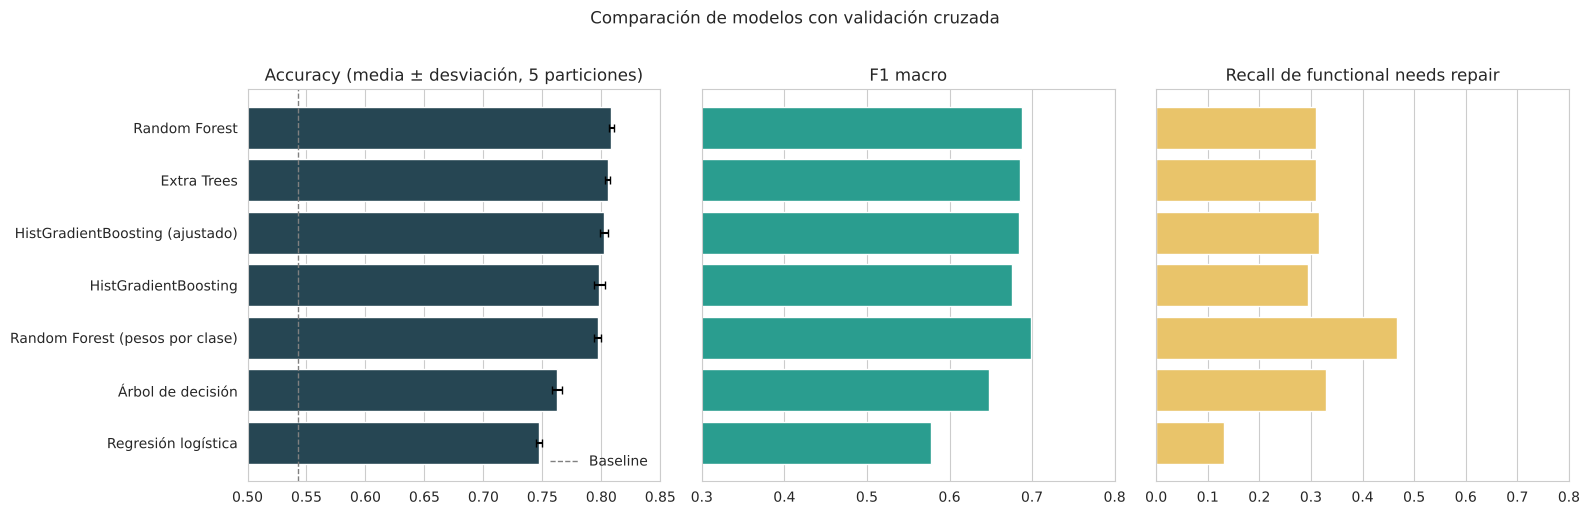

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
orden = comparacion.sort_values('accuracy_media')
baseline_acc = resultados['Baseline (clase mayoritaria)']

axes[0].barh(orden['modelo'], orden['accuracy_media'], xerr=orden['accuracy_desv'], color='#264653', capsize=3)
axes[0].axvline(baseline_acc, color='grey', linestyle='--', linewidth=1, label='Baseline')
axes[0].set_xlim(0.5, 0.85)
axes[0].set_title('Accuracy (media ± desviación, 5 particiones)')
axes[0].legend(frameon=False, loc='lower right')

axes[1].barh(orden['modelo'], orden['f1_macro'], color='#2a9d8f')
axes[1].set_xlim(0.3, 0.8)
axes[1].set_title('F1 macro')

axes[2].barh(orden['modelo'], orden['recall_needs_repair'], color=COLORES['functional needs repair'])
axes[2].set_xlim(0, 0.8)
axes[2].set_title('Recall de functional needs repair')

for ax in axes:
    ax.grid(axis='y', visible=False)
plt.suptitle('Comparación de modelos con validación cruzada', y=1.02)
plt.tight_layout()
plt.show()

Todos los modelos superan con claridad el baseline (54.3%), pero hay diferencias importantes entre familias:

- **Random Forest** obtiene el mejor accuracy medio (0.8085 ± 0.0024), seguido muy de cerca por **Extra Trees** (0.8054) y **HistGradientBoosting ajustado** (0.8023). Las diferencias entre estos tres son de menos de un punto, del mismo orden que su variación entre particiones.
- La **regresión logística** (0.7474) y el **árbol de decisión** individual (0.7623) quedan claramente por detrás. El modelo lineal es además el que peor detecta **functional needs repair** (recall 0.13). Esto indica que el estado de la bomba depende de interacciones no lineales entre variables (por ejemplo, cantidad de agua, tipo de extracción y ubicación), que los ensembles de árboles capturan mejor.
- **Random Forest con pesos por clase** pierde algo más de un punto de accuracy (0.7970), pero sube el recall de **functional needs repair** de 0.31 a 0.47 y tiene el mejor F1 macro (0.6992).

Como la métrica de la competición es el accuracy, mantengo Random Forest como modelo principal y en la siguiente sección afino sus hiperparámetros. Analizo el efecto de los pesos por clase en la evaluación final.

Nota: en la validación cruzada, las estadísticas de imputación y de frecuencia se calcularon con todo el conjunto de entrenamiento interno y no dentro de cada partición. El efecto es pequeño y afecta igual a todos los modelos, así que la comparación entre ellos sigue siendo válida.

#### 8. Ajuste de hiperparámetros

In [25]:
configuraciones = [
    dict(n_estimators=500, min_samples_leaf=1, max_features='sqrt', max_depth=None),
    dict(n_estimators=500, min_samples_leaf=1, max_features=0.3,    max_depth=None),
    dict(n_estimators=500, min_samples_leaf=2, max_features='sqrt', max_depth=None),
    dict(n_estimators=500, min_samples_leaf=1, max_features='sqrt', max_depth=25),
]

accuracies_tuning = []
for cfg in configuraciones:
    pipe = Pipeline([
        ('pre', preprocesador),
        ('clf', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **cfg))
    ])
    pipe.fit(X_train, y_train)
    acc = accuracy_score(y_val, pipe.predict(X_val))
    accuracies_tuning.append(acc)

tabla_tuning = pd.DataFrame(configuraciones)
tabla_tuning['accuracy'] = accuracies_tuning
tabla_tuning = tabla_tuning.sort_values('accuracy', ascending=False).reset_index(drop=True)
tabla_tuning

,n_estimators,min_samples_leaf,max_features,max_depth,accuracy
0,500,2,sqrt,NaN,0.817172
1,500,1,sqrt,25.0,0.811785
2,500,1,sqrt,NaN,0.808923
3,500,1,0.3,NaN,0.807828


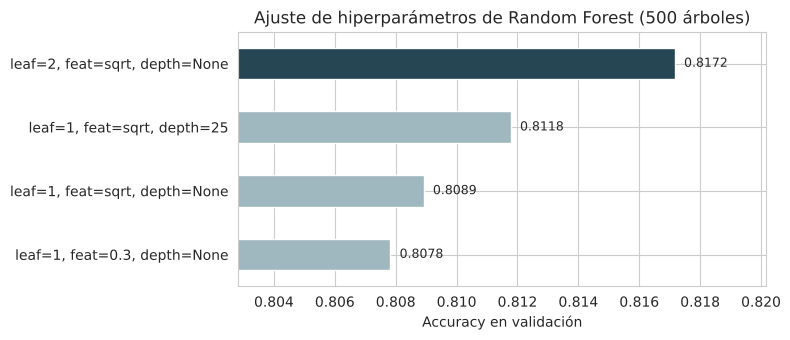

In [26]:
etiquetas = [f"leaf={c['min_samples_leaf']}, feat={c['max_features']}, depth={c['max_depth']}" for c in configuraciones]
serie_tuning = pd.Series(accuracies_tuning, index=etiquetas).sort_values()
fig, ax = plt.subplots(figsize=(8, 3.5))
serie_tuning.plot(kind='barh', color=['#9fb7bf'] * (len(serie_tuning) - 1) + ['#264653'], ax=ax)
ax.set_xlim(serie_tuning.min() - 0.005, serie_tuning.max() + 0.003)
ax.set_xlabel('Accuracy en validación')
ax.set_title('Ajuste de hiperparámetros de Random Forest (500 árboles)')
for i, v in enumerate(serie_tuning):
    ax.text(v + 0.0003, i, f'{v:.4f}', va='center', fontsize=9)
plt.tight_layout()
plt.show()

La mejor combinación es n_estimators=500, min_samples_leaf=2, max_features=sqrt, max_depth=None. El factor que más mejora aporta es min_samples_leaf=2 frente a min_samples_leaf=1: exigir al menos 2 muestras por hoja evita que los árboles memoricen casos aislados del ruido de entrenamiento, a costa de una generalización algo peor si se deja en 1. Limitar max_depth a 25 empeora ligeramente respecto a dejarlo sin límite.

En un intento previo habia usado un n_estimators de 300 y me dio el mismo resultado en el leaderboard en la competición, pero el accuracy de mi modelo (en validación) subio de 0.8169 a 0.8172 al pasar a 500. Aunque me podría haber quedado con 300 (ya que en la competicion el score real fue idéntico), decidi quedarme con 500 porque el accuracy interno mejoró y el coste adicional de entrenamiento es pequeño. También probé subir min_samples_leaf a 3, pero el resultado no fue mejor que con min_samples_leaf=2.

Si el tiempo de entrenamiento fuera una limitación real, 300 árboles seguirían siendo una alternativa razonable.


In [27]:
mejor_idx = int(np.argmax(accuracies_tuning))
mejores_paramtrs = configuraciones[mejor_idx]
print('Mejores hiperparametros:', mejores_paramtrs)

modelo_final_pipe = Pipeline([
    ('pre', preprocesador),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **mejores_paramtrs))
])
modelo_final_pipe.fit(X_train, y_train)
val_pred = modelo_final_pipe.predict(X_val)
acc_final = accuracy_score(y_val, val_pred)
print(f'Accuracy en validación del modelo final: {acc_final:.4f}')

Mejores hiperparametros: {'n_estimators': 500, 'min_samples_leaf': 2, 'max_features': 'sqrt', 'max_depth': None}


Accuracy en validación del modelo final: 0.8172


#### 9. Evaluación del modelo (Random Forest) final

In [28]:
print(classification_report(y_val, val_pred))

                         precision    recall  f1-score   support

             functional       0.81      0.91      0.86      6452
functional needs repair       0.62      0.30      0.41       863
         non functional       0.85      0.78      0.82      4565

               accuracy                           0.82     11880
              macro avg       0.76      0.66      0.69     11880
           weighted avg       0.81      0.82      0.81     11880



El modelo identifica correctamente el 91% (F1 = 0.86) de las bombas realmente funcionales. Es la clase que mejor predice, coherente con ser la mayoritaria.

El modelo solo recupera un 30% (F1 = 0.40) de los casos reales de **functional needs repair**. Es el comportamiento esperable ante una clase minoritaria con apenas el 7.3% de los datos.

El modelo da un buen resultado para **non functional** con 78% (F1 = 0.82)identificados correctamente, aunque me preocupa el error de confundir bombas realmente rotas con **functional**.


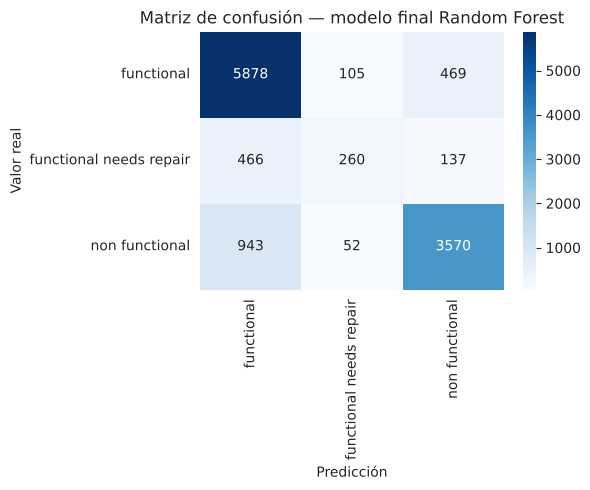

In [29]:
cm = confusion_matrix(y_val, val_pred, labels=modelo_final_pipe.classes_)
fig, ax = plt.subplots(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=modelo_final_pipe.classes_, yticklabels=modelo_final_pipe.classes_, ax=ax)
ax.set_xlabel('Predicción')
ax.set_ylabel('Valor real')
ax.set_title('Matriz de confusión — modelo final Random Forest')
plt.tight_layout()
plt.show()

Accuracy  final: 0.8172  |  con pesos: 0.8028


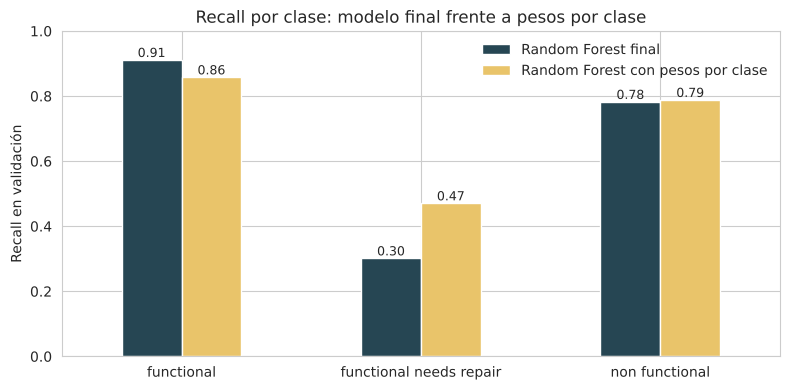

In [30]:
#¿Ayudan los pesos por clase a detectar las bombas que necesitan reparación?
modelo_pesos = Pipeline([
    ('pre', preprocesador),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, class_weight='balanced_subsample',
                                   **mejores_paramtrs))
])
modelo_pesos.fit(X_train, y_train)
pred_pesos = modelo_pesos.predict(X_val)

recall_clases = pd.DataFrame({
    'Random Forest final': recall_score(y_val, val_pred, labels=ESTADOS, average=None),
    'Random Forest con pesos por clase': recall_score(y_val, pred_pesos, labels=ESTADOS, average=None),
}, index=ESTADOS)
print(f"Accuracy  final: {accuracy_score(y_val, val_pred):.4f}  |  con pesos: {accuracy_score(y_val, pred_pesos):.4f}")

fig, ax = plt.subplots(figsize=(8, 4))
recall_clases.plot(kind='bar', color=['#264653', '#e9c46a'], ax=ax, rot=0)
ax.set_ylim(0, 1)
ax.set_ylabel('Recall en validación')
ax.set_title('Recall por clase: modelo final frente a pesos por clase')
for cont in ax.containers:
    ax.bar_label(cont, fmt='%.2f', fontsize=9)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

Con los mismos hiperparámetros, añadir **class_weight='balanced_subsample'** cambia el equilibrio entre clases en validación:

- El recall de **functional needs repair** sube de 0.30 a 0.47.
- El de **functional** baja de 0.91 a 0.86, y el de **non functional** se mantiene (0.78 frente a 0.79).
- El accuracy global baja de 0.8172 a 0.8028.

Para la competición conviene el modelo sin pesos, porque solo se evalúa el accuracy. Sin embargo, en un uso real, donde el objetivo es enviar técnicos antes de que una bomba deje de funcionar, el modelo con pesos sería preferible: detecta muchas más bombas que necesitan reparación a cambio de algunas falsas alarmas en las que sí funcionan.

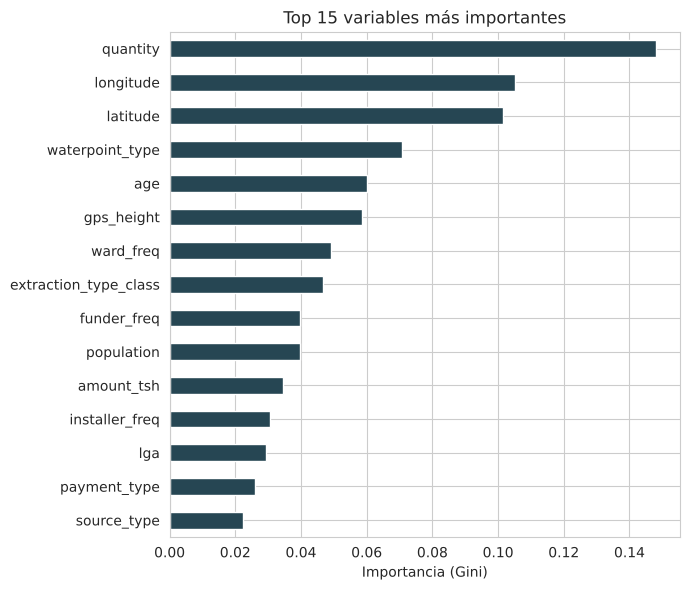

In [31]:
importancias = pd.Series(
    modelo_final_pipe.named_steps['clf'].feature_importances_,
    index=cat_cols + num_cols
).sort_values(ascending=False)

importancias.head(15)

fig, ax = plt.subplots(figsize=(7,6))
importancias.head(15).sort_values().plot(kind='barh', color='#264653', ax=ax)
ax.set_title('Top 15 variables más importantes')
ax.set_xlabel('Importancia (Gini)')
plt.tight_layout()
plt.show()

Las variables con más peso son **quantity, longitude, latitude, waterpoint_type, age**, seguidas de cerca por **gps_height**.

Tiene sentido desde el punto de vista de dominio. La disponibilidad de agua es un indicador directo del estado de la bomba, la ubicación probablemente actúa como proxy de factores regionales de mantenimineto e infraestructura y que **ward_freq** entre en el top 10 confirma que el frequency encoding sirvió.

Que **age** apareza en el top 5 confirma que mereció la pena construirla y refuerza la decisión de haber eliminado **construction_year** en su favor.

#### 10. Entrenamiento final y predicciónes

In [32]:
stats_prod = ajustar_estadisticas(train_base)

X = aplicar_estadisticas(train_base, stats_prod).drop(columns=['id'])
X_test = aplicar_estadisticas(test_base, stats_prod).drop(columns=['id'])
y = y_full

#Verificacion rapida
print('ward_freq mediana en train:', X['ward_freq'].median())
print('ward_freq mediana en test :', X_test['ward_freq'].median())

modelo_produccion = Pipeline([
    ('pre', preprocesador),
    ('clf', RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1, **mejores_paramtrs))
])
modelo_produccion.fit(X, y)

test_pred = modelo_produccion.predict(X_test)

submission = pd.DataFrame({
    'id': test_base['id'],
    'status_group': test_pred
})
print(submission['status_group'].value_counts())

ward_freq mediana en train: 43.0
ward_freq mediana en test : 42.0


status_group
functional                 8989
non functional             5301
functional needs repair     560
Name: count, dtype: int64


In [33]:
submission.to_csv('submission.csv', index=False)

#### 11. Conclusiones

**Resultado del modelo.** El modelo final es un Random Forest de 500 árboles con min_samples_leaf=2 y max_features='sqrt'. Alcanza un accuracy de 0.8172 en validación, frente al 0.5431 de predecir siempre la clase mayoritaria. En la comparación con validación cruzada fue el mejor de los siete modelos probados, aunque Extra Trees y HistGradientBoosting quedaron muy cerca. Los modelos lineales y los árboles individuales quedaron claramente por debajo.

**Qué explica que una bomba falle.** Tanto el análisis exploratorio como la importancia de variables señalan los mismos factores:
- La **disponibilidad de agua** (**quantity**) es el factor más determinante: casi todas las bombas secas aparecen como no funcionales.
- La **ubicación** importa mucho: el porcentaje de bombas no funcionales va del 19.5% en Iringa al 64.2% en Lindi.
- La **antigüedad** (**age**) está fuertemente asociada al fallo: el 63% de las bombas de los años 60 no funcionan, frente al 22% de las construidas desde 2010.
- El **tipo de punto de agua y de extracción**, y el **modo de pago**, también separan los grupos.

**Implicaciones para la salud pública.** Un 38.4% de las bombas del conjunto de entrenamiento no funcionan. Eso se traduce en comunidades sin acceso a agua potable cercana, con el riesgo de enfermedades transmitidas por el agua que eso conlleva. Un modelo como este podría ayudar al Ministerio de Agua a priorizar las inspecciones: empezar por las regiones con más fallos, las bombas más antiguas y los puntos con poca agua. Para ese uso, la versión con pesos por clase es más útil, porque detecta casi la mitad de las bombas que necesitan reparación en lugar de un 30%.

**Limitaciones.**
- La clase **functional needs repair** sigue siendo difícil de predecir (recall de 0.30 con el modelo final). Representa solo el 7.3% de los datos y no tiene un patrón claro por antigüedad ni por tipo de bomba.
- Más de un tercio de los registros tienen **construction_year**, **gps_height** o **population** en cero. Los he imputado con la mediana de la región, lo que introduce incertidumbre en esas variables.
- Los datos se registraron entre 2011 y 2013, así que el modelo describe la situación de ese momento y no tiene por qué servir igual para bombas actuales.
- Los resultados son asociaciones: el modelo no permite afirmar que, por ejemplo, cambiar el modo de pago mejore el estado de las bombas.

**Próximos pasos.** Probaría a ajustar más a fondo HistGradientBoosting, que quedó cerca de Random Forest con muy pocas pruebas; usar target encoding para las variables de alta cardinalidad como **funder** e **installer**; y ajustar los umbrales de decisión por clase para encontrar un mejor equilibrio entre detectar reparaciones y mantener el accuracy.